In [17]:
import numpy as np
import pandas as pd
from sklearn.model_selection import train_test_split
import matplotlib.pyplot as plt
from sklearn.metrics import mean_absolute_error, r2_score
from sklearn.linear_model import LinearRegression





In [10]:
df = pd.read_csv('/content/dataset/insurance.csv')
print(df.shape)
print(df.head())


(1338, 7)
   age     sex     bmi  children smoker     region      charges
0   19  female  27.900         0    yes  southwest  16884.92400
1   18    male  33.770         1     no  southeast   1725.55230
2   28    male  33.000         3     no  southeast   4449.46200
3   33    male  22.705         0     no  northwest  21984.47061
4   32    male  28.880         0     no  northwest   3866.85520


In [11]:
y = df_encoded["charges"]
X = df_encoded.drop(columns=["charges"])
print("X shape:", X.shape)
print("y shape:", y.shape)
print(X.head())

X shape: (1338, 8)
y shape: (1338,)
   age     bmi  children  sex_male  smoker_yes  region_northwest  \
0   19  27.900         0     False        True             False   
1   18  33.770         1      True       False             False   
2   28  33.000         3      True       False             False   
3   33  22.705         0      True       False              True   
4   32  28.880         0      True       False              True   

   region_southeast  region_southwest  
0             False              True  
1              True             False  
2              True             False  
3             False             False  
4             False             False  


In [12]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, random_state=42,test_size=0.2
)
print(X_test.shape)
print(X_train.shape)


(268, 8)
(1070, 8)


In [13]:
X1 = X[["age"]]
Xtr, Xte, ytr, yte = train_test_split(
    X1, y, test_size=0.2, random_state=40
)
simple = LinearRegression()
simple.fit(Xtr, ytr)
pred = simple.predict(Xte)
print("Intercept:", simple.intercept_)
print("Slope:", simple.coef_[0])
print("First 5 predictions:", pred[:6])

Intercept: 3055.284599068911
Slope: 260.20324993094516
First 5 predictions: [ 9560.36584734  7738.94309783 13723.61784624 15805.24384569
  9300.16259741 13463.41459631]


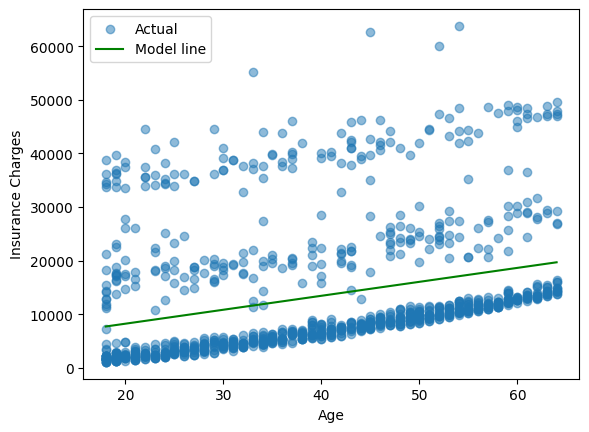

In [14]:
pred_train = simple.predict(Xtr)
order = np.argsort(Xtr["age"].values)
plt.scatter(Xtr["age"], ytr, label="Actual", alpha=0.5)
plt.plot(
    Xtr["age"].values[order],
    pred_train[order],
    color="green", label="Model line"
)
plt.xlabel("Age")
plt.ylabel("Insurance Charges")
plt.legend()
plt.show()

In [15]:
multiple = LinearRegression()
multiple.fit(X_train, y_train)
pred_multi = multiple.predict(X_test)
print("Intercept:", multiple.intercept_)
print("Coefficients:", multiple.coef_)
print("First predictions:", pred_multi[:6])

Intercept: -11931.21905032666
Coefficients: [ 2.56975706e+02  3.37092552e+02  4.25278784e+02 -1.85916916e+01
  2.36511289e+04 -3.70677326e+02 -6.57864297e+02 -8.09799354e+02]
First predictions: [ 8969.55027444  7068.74744287 36858.41091155  9454.67850053
 26973.17345656 10864.11316424]


In [16]:
print("Predicted:", pred_multi[:10])
print("Actual:", y_test.values[:10])


mae = mean_absolute_error(y_test, pred_multi)
r2 = r2_score(y_test, pred_multi)
print("R2:", round(r2, 4))
print("MAE:", round(mae, 2))

Predicted: [ 8969.55027444  7068.74744287 36858.41091155  9454.67850053
 26973.17345656 10864.11316424   170.28084136 16903.45028662
  1092.43093614 11218.34318352]
Actual: [ 9095.06825  5272.1758  29330.98315  9301.89355 33750.2918   4536.259
  2117.33885 14210.53595  3732.6251  10264.4421 ]
R2: 0.7836
MAE: 4181.19
